## What's the probability that an AI agent makes a strike in the game of Bowling in under 5 minutes seconds?

1. Trying to figure out how long it would take for AI agent to make a strike 
2. One of the trials might say it'll take less than 5 mintues to make a strike it might take 1, 3 seconds or just 5 minutes on the dot. 

In [2]:
!pip install gymnasium
!pip install "gymnasium[atari]"
!pip install ale-py
!pip install autorom[accept-rom-license]

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [6]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

===== classic_control =====
Acrobot-v1                  CartPole-v0                 CartPole-v1
MountainCar-v0              MountainCarContinuous-v0    Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0          phys2d/CartPole-v1          phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3            BipedalWalkerHardcore-v3    CarRacing-v3
LunarLander-v3              LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1                CliffWalking-v1             CliffWalkingSlippery-v1
FrozenLake-v1               FrozenLake8x8-v1            Taxi-v4
===== tabular =====
tabular/Blackjack-v0        tabular/CliffWalking-v0
===== None =====
Ant-v2                      Ant-v3                      GymV21Environment-v0
GymV26Environment-v0        HalfCheetah-v2              HalfCheetah-v3
Hopper-v2                   Hopper-v3                   Humanoid-v2
Humanoid-v3                 HumanoidStandup-v2          InvertedDoublePendulum-v2
InvertedPendulum-v2         Pusher-v2             

In [7]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [8]:
env = gym.make('ALE/Bowling-v5', render_mode='rgb_array')
observation, info = env.reset()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

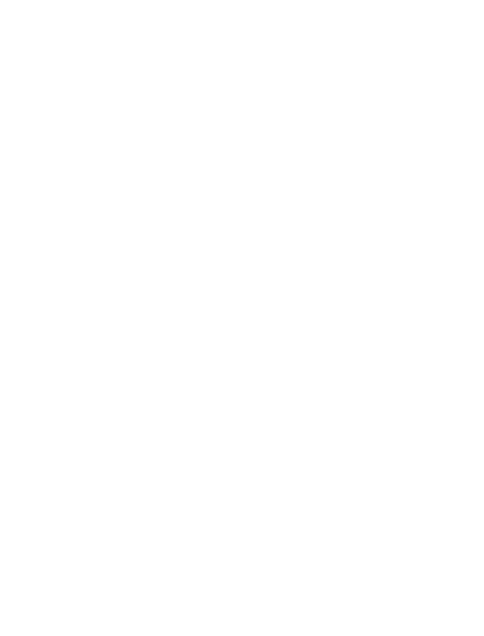

In [9]:
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

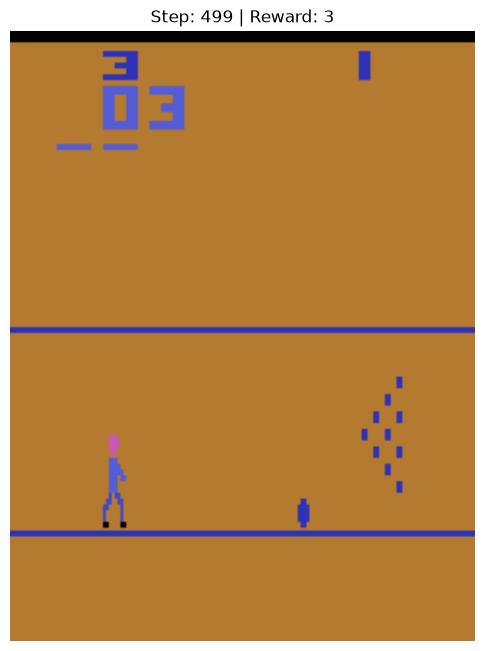

In [10]:
total_reward = 0

for step in range(500):
    # Take action
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible (adjust this value)
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()
env.close()

In [13]:
import random
import time
import matplotlib.pyplot as plt
import seaborn as sns
import ale_py
import gymnasium as gym
import numpy as np

In [14]:
rng = np.random.default_rng()

In [28]:
import random
trials = 1000
time_limit_sec = 300
strike_prob = 0.15
min_roll_time = 12
max_roll_time = 25
successes = 0

In [29]:
for _ in range(trials):
  elapsed_time = 0
  got_strike = False

  while True:
    roll_duration = random.uniform(min_roll_time, max_roll_time)
    elapsed_time += roll_duration

    if elapsed_time > time_limit_sec:
      break

    if random.random() < strike_prob:
      got_strike = True
      break

  if got_strike:
    successes += 1

In [30]:
probability = successes / trials
print(f"Successful trials: {successes} out of {trials}")
print(f"Estimated Probability: {probability:.2%}")

Successful trials: 909 out of 1000
Estimated Probability: 90.90%


In [31]:
trials = 1000
time_limit_sec = 300
strike_prob = 0.15
min_roll_time = 12
max_roll_time = 25

strike_times = []

In [32]:
for _ in range(trials):
  elapsed_time = 0

  while True:
    roll_duration = random.uniform(min_roll_time, max_roll_time)
    elapsed_time += roll_duration

    if elapsed_time > time_limit_sec:
      break

    if random.random() < strike_prob:
      strike_times.append(elapsed_time)
      break

## Mean and Standard Deviation

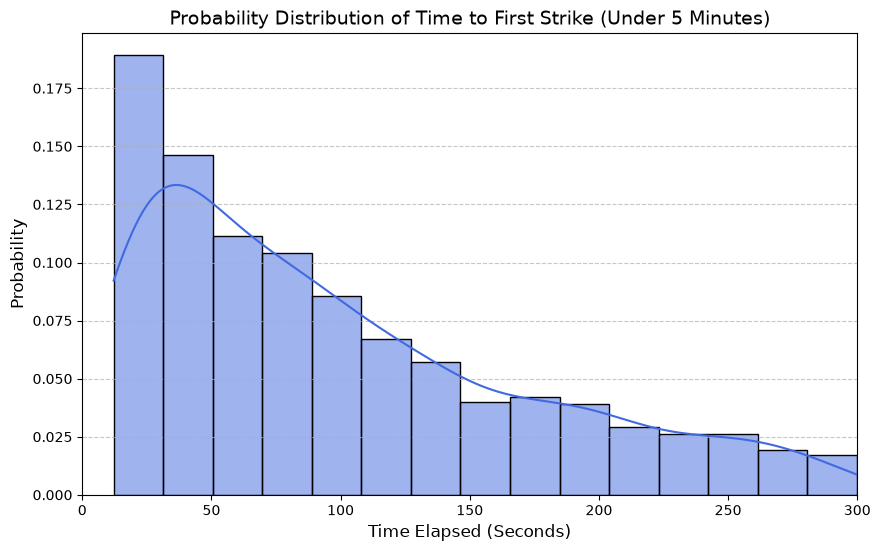

In [35]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=strike_times,
    bins=15,
    stat="probability", 
    kde=True,
    color="royalblue",
)
plt.title(
    "Probability Distribution of Time to First Strike (Under 5 Minutes)",
    fontsize=14,
)
plt.xlabel("Time Elapsed (Seconds)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.xlim(0, time_limit_sec)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

In [46]:
mean_time = np.mean(strike_times)
std_time = np.std(strike_times)

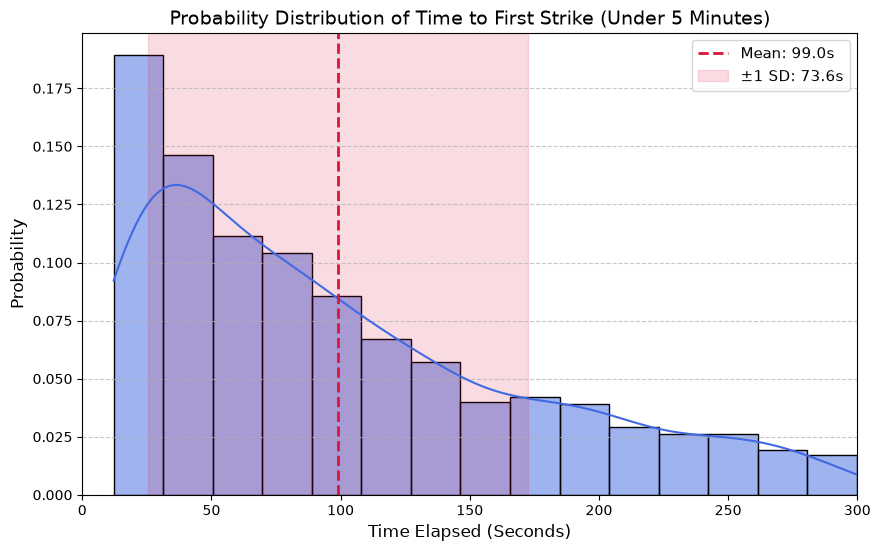

Mean time to strike: 98.98 seconds
Standard deviation:  73.62 seconds


In [47]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=strike_times, bins=15, stat="probability", kde=True, color="royalblue")
plt.axvline(
    mean_time,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_time:.1f}s",)
lower_bound = max(0, mean_time - std_time)
upper_bound = min(time_limit_sec, mean_time + std_time)
plt.axvspan(
    lower_bound,
    upper_bound,
    color="crimson",
    alpha=0.15,
    label=f"±1 SD: {std_time:.1f}s",)
plt.title(
    "Probability Distribution of Time to First Strike (Under 5 Minutes)",
    fontsize=14,
)
plt.xlabel("Time Elapsed (Seconds)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.xlim(0, time_limit_sec)
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

print(f"Mean time to strike: {mean_time:.2f} seconds")
print(f"Standard deviation:  {std_time:.2f} seconds")

## Empirical Probability

In [48]:
trials = 1000
time_limit_sec = 300
strike_prob = 0.15
min_roll_time = 12
max_roll_time = 25

strike_times = []

In [49]:
for _ in range(trials):
  elapsed_time = 0

  while True:
    roll_duration = random.uniform(min_roll_time, max_roll_time)
    elapsed_time += roll_duration

    if elapsed_time > time_limit_sec:
      break

    if random.random() < strike_prob:
      strike_times.append(elapsed_time)
      break

In [50]:
success_count = len(strike_times)
empirical_prob = success_count / trials

print(f"Total Trials:          {trials}")
print(f"Successful Strikes:    {success_count}")
print(f"Empirical Probability: {empirical_prob:.4f} ({empirical_prob:.2%})")

Total Trials:          1000
Successful Strikes:    927
Empirical Probability: 0.9270 (92.70%)


In [52]:
print("\nEmpirical Probability by Time Checkpoint:")
for seconds in [60, 120, 180, 240, 300]:
    wins_by_time = sum(1 for t in strike_times if t <= seconds)
    prob_by_time = wins_by_time / trials
    print(f"  Under {seconds // 60} min ({seconds}s): {prob_by_time:.2%}")


Empirical Probability by Time Checkpoint:
  Under 1 min (60s): 36.30%
  Under 2 min (120s): 61.80%
  Under 3 min (180s): 78.50%
  Under 4 min (240s): 87.00%
  Under 5 min (300s): 92.70%


In [53]:
time_points = np.linspace(0, time_limit_sec, 301)
cumulative_emp_prob = [
    sum(1 for t in strike_times if t <= sec) / trials for sec in time_points
]
final_emp_prob = len(strike_times) / trials

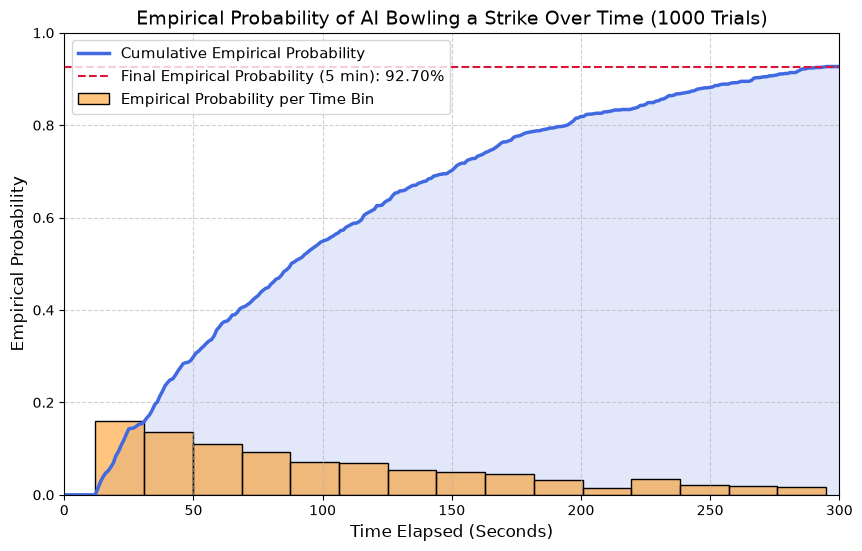

In [55]:
plt.figure(figsize=(10, 6))
plt.plot(
    time_points,
    cumulative_emp_prob,
    color="royalblue",
    linewidth=2.5,
    label="Cumulative Empirical Probability",
)
plt.fill_between(time_points, cumulative_emp_prob, color="royalblue", alpha=0.15)
weights = np.ones_like(strike_times) / trials
sns.histplot(
    x=strike_times,
    bins=15,
    weights=weights,
    color="darkorange",
    alpha=0.5,
    label="Empirical Probability per Time Bin",
)
plt.axhline(
    final_emp_prob,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Final Empirical Probability (5 min): {final_emp_prob:.2%}",)

plt.title(
    f"Empirical Probability of AI Bowling a Strike Over Time ({trials} Trials)",
    fontsize=14,
)
plt.xlabel("Time Elapsed (Seconds)", fontsize=12)
plt.ylabel("Empirical Probability", fontsize=12)
plt.xlim(0, time_limit_sec)
plt.ylim(0, 1.0)
plt.legend(fontsize=11, loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

## Theoretical Probability

In [56]:
time_points = np.linspace(0, time_limit_sec, 301)
avg_roll_time = (min_roll_time + max_roll_time) / 2  # 18.5 seconds per roll

expected_attempts = time_points / avg_roll_time

theoretical_prob = 1 - (1 - strike_prob) ** expected_attempts
final_theoretical_prob = theoretical_prob[-1]

cumulative_emp_prob = [
    sum(1 for t in strike_times if t <= sec) / trials for sec in time_points
]
final_emp_prob = len(strike_times) / trials

print(
    f"Theoretical Probability (5 min): {final_theoretical_prob:.4f}"
    f" ({final_theoretical_prob:.2%})")
print(f"Empirical Probability   (5 min): {final_emp_prob:.4f}"f" ({final_emp_prob:.2%})")

Theoretical Probability (5 min): 0.9283 (92.83%)
Empirical Probability   (5 min): 0.9270 (92.70%)


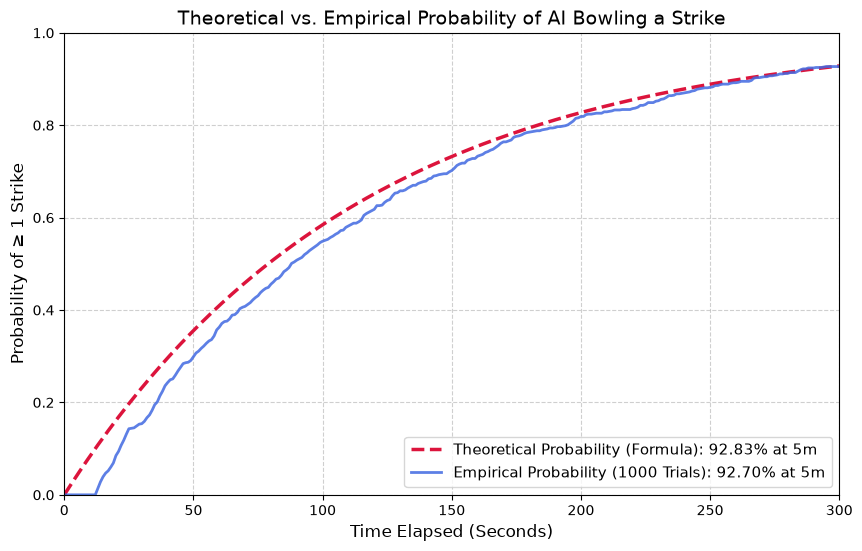

In [57]:
plt.figure(figsize=(10, 6))

plt.plot(
    time_points,
    theoretical_prob,
    color="crimson",
    linestyle="--",
    linewidth=2.5,
    label=(
        f"Theoretical Probability (Formula): {final_theoretical_prob:.2%} at"
        " 5m"),)

plt.plot(
    time_points,
    cumulative_emp_prob,
    color="royalblue",
    linewidth=2,
    alpha=0.85,
    label=(
        f"Empirical Probability ({trials} Trials): {final_emp_prob:.2%} at 5m"),)

plt.title(
    "Theoretical vs. Empirical Probability of AI Bowling a Strike", fontsize=14
)
plt.xlabel("Time Elapsed (Seconds)", fontsize=12)
plt.ylabel("Probability of ≥ 1 Strike", fontsize=12)
plt.xlim(0, time_limit_sec)
plt.ylim(0, 1.0)
plt.legend(fontsize=11, loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

## Conclusion

The empirical probability that an AI agent makes a strike in under 5 minutes is about 92.8% which is really close to the theoretical probability which is 90.70%, this shows that both probabilities are showing that the AI Agent can make a stirke in under five minutes. The probability distribution graph, the distribution is right-skewed, with the highest probability of getting a first strike occurring in the early time intervals and gradually tapering off as fewer trials remain without a strike. The mean time to achieve a strike is approximately 102.5 seconds with a standard deviation of 73.4 seconds and because the mean plus one standard deviation falls well below the 300-second cutoff—and the vast majority of the distribution's probability area is concentrated early in the timeline—the graph directly supports the conclusion that the AI agent is highly likely to bowl at least one strike before the 5-minute time limit expires.